# 🔴 Práctica: Análisis y Visualización de Calificaciones
## con Pandas y Matplotlib — Estilo Cyberpunk

---

**Ingeniería en Sistemas Computacionales (ISC)**  
**Dataset:** `calificaciones_isc.csv` — 288 registros · 24 alumnos · 4 materias · 3 unidades  

| Ejercicio | Tema |
|-----------|------|
| 1 | Carga y revisión inicial del DataFrame |
| 2 | Filtros vectorizados sin bucles |
| 3 | Columna calculada con `np.where` |
| 4 | Resúmenes con `groupby` y exportación CSV |
| 5 | Gráficas con tema Cyberpunk |
| 6 | Interpretación y conclusiones |

---
## ⚙️ Configuración Inicial

Importamos las librerías y definimos la **paleta Cyberpunk** que se aplicará de forma global a todos los plots de Matplotlib mediante `rcParams`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── PALETA CYBERPUNK ─────────────────────────────────────────────────────────
BG      = "#000000"   # fondo principal (negro puro)
ACCENT  = "#ff1e42"   # rojo neón primario
ACCENT2 = "#ff6b81"   # rojo neón secundario
ACCENT3 = "#ff9eb5"   # rojo neón terciario
ACCENT4 = "#ffccd5"   # rosado muy claro
WHITE   = "#ffffff"   # texto y etiquetas
GRID    = "#2a0008"   # rejilla sutil
COLORS  = [ACCENT, ACCENT2, ACCENT3, ACCENT4]  # paleta por materia

# ── TEMA GLOBAL MATPLOTLIB ───────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor":  BG,
    "axes.facecolor":    BG,
    "savefig.facecolor": BG,
    "text.color":        WHITE,
    "axes.labelcolor":   WHITE,
    "xtick.color":       WHITE,
    "ytick.color":       WHITE,
    "axes.titlecolor":   WHITE,
    "legend.facecolor":  "#0d0d0d",
    "legend.edgecolor":  ACCENT,
    "legend.labelcolor": WHITE,
    "axes.grid":         True,
    "grid.color":        GRID,
    "grid.linewidth":    0.8,
    "grid.linestyle":    "--",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.edgecolor":    ACCENT,
    "font.family":       "monospace",
    "axes.titlesize":    14,
    "axes.labelsize":    11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "figure.dpi":        130,
})

# ── CONSTANTES ───────────────────────────────────────────────────────────────
CSV_FILE = "calificaciones_isc.csv"
OUT_BAR  = "promedio_materias.png"
OUT_HIST = "histograma.png"
OUT_LINE = "tendencia_unidades.png"
OUT_PROM = "promedios_alumnos.csv"

print("Configuracion Cyberpunk cargada correctamente.")

Configuracion Cyberpunk cargada correctamente.


---
## 🗃️ Generación del Dataset

Si `calificaciones_isc.csv` **no existe**, se genera automáticamente un dataset realista con:
- **24 alumnos** → 12 en Grupo A · 12 en Grupo B
- **4 materias** → Programacion, Bases de datos, Redes, Matematicas discretas
- **3 unidades** por materia
- **Columnas:** `matricula`, `nombre`, `grupo`, `materia`, `unidad`, `calificacion` (0-100), `asistencias`

Total: 24 × 4 × 3 = **288 filas**

In [2]:
def generar_dataset():
    """Genera calificaciones_isc.csv con 288 filas realistas."""
    rng = np.random.default_rng(42)  # semilla fija para reproducibilidad

    nombres_a = [
        ("ISC240101", "Ana Garcia Lopez"),
        ("ISC240102", "Carlos Mendez Ruiz"),
        ("ISC240103", "Diana Torres Silva"),
        ("ISC240104", "Eduardo Ramirez Vega"),
        ("ISC240105", "Fernanda Lopez Cruz"),
        ("ISC240106", "Gabriel Hernandez Diaz"),
        ("ISC240107", "Hana Martinez Soto"),
        ("ISC240108", "Ivan Flores Perez"),
        ("ISC240109", "Julia Castillo Moreno"),
        ("ISC240110", "Kevin Vargas Reyes"),
        ("ISC240111", "Lucia Guerrero Campos"),
        ("ISC240112", "Miguel Angel Fuentes"),
    ]
    nombres_b = [
        ("ISC240113", "Nadia Romero Blanco"),
        ("ISC240114", "Oscar Delgado Lara"),
        ("ISC240115", "Pamela Jimenez Rojas"),
        ("ISC240116", "Quetzal Morales Juarez"),
        ("ISC240117", "Rodrigo Salinas Gomez"),
        ("ISC240118", "Sofia Aguilar Nieto"),
        ("ISC240119", "Tomas Espinoza Leon"),
        ("ISC240120", "Ursula Valdez Mendez"),
        ("ISC240121", "Victor Rios Sandoval"),
        ("ISC240122", "Wendy Ochoa Ibarra"),
        ("ISC240123", "Ximena Pena Castro"),
        ("ISC240124", "Yael Ramos Serrano"),
    ]
    materias = ["Programacion", "Bases de datos", "Redes", "Matematicas discretas"]
    unidades = [1, 2, 3]

    filas = []
    for grupo, alumnos in [("A", nombres_a), ("B", nombres_b)]:
        for matricula, nombre in alumnos:
            base = float(np.clip(rng.normal(75, 12), 40, 100))
            for materia in materias:
                ajuste_mat = {"Programacion": rng.normal(0, 5),
                              "Bases de datos": rng.normal(-3, 5),
                              "Redes": rng.normal(2, 5),
                              "Matematicas discretas": rng.normal(-8, 7)}[materia]
                for unidad in unidades:
                    ajuste_u = (unidad - 1) * rng.normal(1, 3)
                    cal = float(np.clip(round(base + ajuste_mat + ajuste_u + rng.normal(0, 4), 1), 0, 100))
                    asist = int(np.clip(round(cal / 10 * 1.6 + rng.normal(0, 1)), 0, 16))
                    filas.append({"matricula": matricula, "nombre": nombre,
                                  "grupo": grupo, "materia": materia,
                                  "unidad": unidad, "calificacion": cal,
                                  "asistencias": asist})

    df = pd.DataFrame(filas)
    df.to_csv(CSV_FILE, index=False, encoding="utf-8-sig")
    print(f"[OK] Dataset generado: {CSV_FILE} ({len(df)} filas)")
    return df


# Generar solo si no existe
if not os.path.exists(CSV_FILE):
    generar_dataset()
else:
    print(f"[OK] Dataset ya existe: {CSV_FILE}")

[OK] Dataset ya existe: calificaciones_isc.csv


---
## 📂 Ejercicio 1 — Carga y Revisión Inicial del DataFrame

Cargamos el CSV con `pd.read_csv()` y exploramos la estructura del DataFrame:
- **`.head()`** → primeras 5 filas
- **`.shape`** → dimensiones (filas, columnas)
- **`.dtypes`** → tipo de dato de cada columna
- **`.describe()`** → estadísticas descriptivas de `calificacion` y `asistencias`

> **¿Por qué 288 filas si solo hay 24 alumnos?**  
> El CSV usa formato **TIDY (largo)**: cada fila representa **una observación única** (alumno + materia + unidad).  
> 24 alumnos × 4 materias × 3 unidades = **288 filas**.  
> Esto permite aplicar `groupby`, `pivot_table` y filtros vectorizados sin necesitar reestructurar los datos.

In [3]:
# Leer el CSV en el DataFrame principal
df = pd.read_csv(CSV_FILE, encoding="utf-8-sig")

print("=" * 58)
print("  EJERCICIO 1 — Carga y Revision Inicial")
print("=" * 58)
print(f"\nShape (filas, columnas): {df.shape}")
print("\n>> Primeras 5 filas:")
df.head()

  EJERCICIO 1 — Carga y Revision Inicial

Shape (filas, columnas): (288, 7)

>> Primeras 5 filas:


,matricula,nombre,grupo,materia,unidad,calificacion,asistencias
0,ISC240101,Ana García López,A,Programacion,1,74.0,12
1,ISC240101,Ana García López,A,Programacion,2,71.0,12
2,ISC240101,Ana García López,A,Programacion,3,80.4,14
3,ISC240101,Ana García López,A,Bases de datos,1,71.2,11
4,ISC240101,Ana García López,A,Bases de datos,2,75.2,12


In [4]:
print(">> Tipos de columnas (dtypes):")
print(df.dtypes.to_string())

>> Tipos de columnas (dtypes):
matricula           str
nombre              str
grupo               str
materia             str
unidad            int64
calificacion    float64
asistencias       int64


In [5]:
print(">> Estadisticas descriptivas — calificacion y asistencias:")
df[["calificacion", "asistencias"]].describe().round(2)

>> Estadisticas descriptivas — calificacion y asistencias:


,calificacion,asistencias
count,288.00,288.0
mean,72.26,11.5
std,13.12,2.4
min,39.30,5.0
25%,62.68,10.0
50%,71.50,11.0
75%,80.18,13.0
max,100.00,16.0


---
## 🔍 Ejercicio 2 — Filtros Vectorizados (sin bucles)

Pandas permite filtrar datos usando **índices booleanos** sin necesitar ningún `for` ni `while`.  
Aplicamos tres filtros:

1. Todos los registros del **Grupo A**
2. Registros con **calificación < 70** (reprobados)
3. **Bases de datos** · **Grupo B** · **calificación ≥ 80** (usando el operador `&` para combinar condiciones)

In [6]:
print("=" * 58)
print("  EJERCICIO 2 — Filtros Vectorizados sin Bucles")
print("=" * 58)

# ── Filtro 1: Grupo A ─────────────────────────────────────────
grupo_a = df[df["grupo"] == "A"]
print(f"\n[1] Registros del Grupo A            : {len(grupo_a)}")

# ── Filtro 2: Calificacion reprobatoria ───────────────────────
reprobados = df[df["calificacion"] < 70]
print(f"[2] Registros con calificacion < 70  : {len(reprobados)}")

# ── Filtro 3: Bases de datos + Grupo B + cal >= 80 ────────────
bd_b_buenos = df[
    (df["materia"]      == "Bases de datos") &
    (df["grupo"]        == "B") &
    (df["calificacion"] >= 80)
]
print(f"[3] Bases de datos | Grupo B | >= 80 : {len(bd_b_buenos)}")

print("\n>> Muestra del Filtro 3:")
bd_b_buenos[["matricula", "nombre", "grupo", "materia", "unidad", "calificacion"]]

  EJERCICIO 2 — Filtros Vectorizados sin Bucles

[1] Registros del Grupo A            : 144
[2] Registros con calificacion < 70  : 123
[3] Bases de datos | Grupo B | >= 80 : 7

>> Muestra del Filtro 3:


,matricula,nombre,grupo,materia,unidad,calificacion
209,ISC240118,Sofía Aguilar Nieto,B,Bases de datos,3,93.0
267,ISC240123,Ximena Peña Castro,B,Bases de datos,1,95.8
268,ISC240123,Ximena Peña Castro,B,Bases de datos,2,100.0
269,ISC240123,Ximena Peña Castro,B,Bases de datos,3,100.0
279,ISC240124,Yael Ramos Serrano,B,Bases de datos,1,92.0
280,ISC240124,Yael Ramos Serrano,B,Bases de datos,2,90.4
281,ISC240124,Yael Ramos Serrano,B,Bases de datos,3,92.5


---
## ➕ Ejercicio 3 — Columna Calculada con `np.where`

Agregamos la columna **`situacion`** de forma vectorizada usando `np.where()`, que funciona como un _if-else_ aplicado a todo el arreglo a la vez:

```python
np.where(condicion, valor_si_true, valor_si_false)
```

- `calificacion >= 70` → **"Aprobado"**
- `calificacion < 70`  → **"Reprobado"**

> ✅ No se usa ningún loop. La operación se aplica sobre las 288 filas en una sola instrucción.

In [7]:
print("=" * 58)
print("  EJERCICIO 3 — Columna Calculada: situacion")
print("=" * 58)

# np.where vectorizado — sin loops
df["situacion"] = np.where(df["calificacion"] >= 70, "Aprobado", "Reprobado")

print("\n>> Primeras 10 filas con la nueva columna 'situacion':")
df[["matricula", "nombre", "materia", "unidad", "calificacion", "situacion"]].head(10)

  EJERCICIO 3 — Columna Calculada: situacion

>> Primeras 10 filas con la nueva columna 'situacion':


,matricula,nombre,materia,unidad,calificacion,situacion
0,ISC240101,Ana García López,Programacion,1,74.0,Aprobado
1,ISC240101,Ana García López,Programacion,2,71.0,Aprobado
2,ISC240101,Ana García López,Programacion,3,80.4,Aprobado
3,ISC240101,Ana García López,Bases de datos,1,71.2,Aprobado
4,ISC240101,Ana García López,Bases de datos,2,75.2,Aprobado
5,ISC240101,Ana García López,Bases de datos,3,69.4,Reprobado
6,ISC240101,Ana García López,Redes,1,80.8,Aprobado
7,ISC240101,Ana García López,Redes,2,90.2,Aprobado
8,ISC240101,Ana García López,Redes,3,76.5,Aprobado
9,ISC240101,Ana García López,Matematicas discretas,1,73.2,Aprobado


---
## 📊 Ejercicio 4 — Resúmenes con `groupby` y Exportación CSV

Usamos `groupby()` para calcular promedios y conteos agrupados:

| Agrupación | Descripción |
|------------|-------------|
| Por **materia** | Promedio general de cada asignatura |
| Por **grupo + materia** | Comparativa A vs B por materia |
| Por **alumno** | Promedio general individual (descendente) |
| Por **unidad** | Promedio de toda la generación por unidad |
| **Aprobados/Reprobados** | Conteo total de `situacion` |

Al final se exporta **`promedios_alumnos.csv`** usando `reset_index()` e `index=False`.

In [8]:
print("=" * 58)
print("  EJERCICIO 4 — Resumenes Estadisticos")
print("=" * 58)

# ── 4.1 Promedio por materia ──────────────────────────────────
prom_materia = df.groupby("materia")["calificacion"].mean().round(2)
print("\n[4.1] Promedio por materia:")
prom_materia

  EJERCICIO 4 — Resumenes Estadisticos

[4.1] Promedio por materia:


materia
Bases de datos           72.36
Matematicas discretas    67.24
Programacion             73.21
Redes                    76.21
Name: calificacion, dtype: float64

In [9]:
# ── 4.2 Promedio por grupo y materia ─────────────────────────
prom_grupo_materia = df.groupby(["grupo", "materia"])["calificacion"].mean().round(2)
print("[4.2] Promedio por grupo y materia:")
prom_grupo_materia.unstack()  # pivot para mejor legibilidad

[4.2] Promedio por grupo y materia:


materia,Bases de datos,Matematicas discretas,Programacion,Redes
grupo,,,,
A,70.41,65.58,70.83,75.86
B,74.31,68.90,75.59,76.56


In [10]:
# ── 4.3 Promedio general por alumno (descendente) ─────────────
# groupby sobre matricula + nombre para conservar ambas columnas en reset_index()
prom_alumno = (
    df.groupby(["matricula", "nombre"])["calificacion"]
      .mean()
      .round(2)
      .sort_values(ascending=False)
)
print("[4.3] Promedio general por alumno (descendente):")
prom_alumno

[4.3] Promedio general por alumno (descendente):


matricula  nombre                
ISC240123  Ximena Peña Castro        95.53
ISC240124  Yael Ramos Serrano        92.52
ISC240106  Gabriel Hernández Díaz    88.98
ISC240108  Iván Flores Pérez         86.74
ISC240107  Hana Martínez Soto        85.01
ISC240118  Sofía Aguilar Nieto       77.30
ISC240121  Víctor Ríos Sandoval      76.62
ISC240101  Ana García López          76.42
ISC240105  Fernanda López Cruz       75.02
ISC240116  Quetzal Morales Juárez    73.90
ISC240114  Oscar Delgado Lara        70.49
ISC240102  Carlos Mendez Ruiz        69.95
ISC240120  Ursula Valdez Méndez      69.02
ISC240119  Tomás Espinoza León       68.04
ISC240109  Julia Castillo Moreno     67.97
ISC240113  Nadia Romero Blanco       67.43
ISC240122  Wendy Ochoa Ibarra        66.15
ISC240117  Rodrigo Salinas Gómez     65.73
ISC240115  Pamela Jiménez Rojas      63.36
ISC240111  Lucía Guerrero Campos     62.78
ISC240110  Kevin Vargas Reyes        60.73
ISC240103  Diana Torres Silva        60.51
ISC240112  Miguel Án

In [11]:
# ── 4.4 Promedio por unidad ──────────────────────────────────
prom_unidad = df.groupby("unidad")["calificacion"].mean().round(2)
print("[4.4] Promedio por unidad:")
print(prom_unidad.to_string())

# ── 4.5 Conteo aprobados / reprobados ────────────────────────
conteo_sit = df["situacion"].value_counts()
print("\n[4.5] Conteo Aprobados / Reprobados:")
print(conteo_sit.to_string())

[4.4] Promedio por unidad:
unidad
1    71.59
2    72.51
3    72.67

[4.5] Conteo Aprobados / Reprobados:
situacion
Aprobado     165
Reprobado    123


In [12]:
# ── 4.6 Exportar promedios por alumno a CSV ───────────────────
# reset_index() convierte el MultiIndex (matricula, nombre) en columnas normales
prom_alumno_df = prom_alumno.reset_index()
prom_alumno_df.columns = ["matricula", "nombre", "promedio_general"]

# index=False evita que pandas escriba el numero de fila como columna extra
prom_alumno_df.to_csv(OUT_PROM, index=False, encoding="utf-8-sig")

print(f"[OK] Exportado -> {OUT_PROM} ({len(prom_alumno_df)} filas)")
prom_alumno_df

[OK] Exportado -> promedios_alumnos.csv (24 filas)


,matricula,nombre,promedio_general
0,ISC240123,Ximena Peña Castro,95.53
1,ISC240124,Yael Ramos Serrano,92.52
2,ISC240106,Gabriel Hernández Díaz,88.98
3,ISC240108,Iván Flores Pérez,86.74
4,ISC240107,Hana Martínez Soto,85.01
5,ISC240118,Sofía Aguilar Nieto,77.30
6,ISC240121,Víctor Ríos Sandoval,76.62
7,ISC240101,Ana García López,76.42
8,ISC240105,Fernanda López Cruz,75.02
9,ISC240116,Quetzal Morales Juárez,73.90


---
## 📈 Ejercicio 5 — Gráficas con Estilo Cyberpunk

Se generan y guardan **3 gráficas PNG** con el tema Cyberpunk definido en `rcParams`:

| Archivo | Tipo | Descripción |
|---------|------|-------------|
| `promedio_materias.png` | Barras | Promedio por materia, eje Y de 0 a 100, línea punteada en 70 |
| `histograma.png` | Histograma | Distribución de todas las calificaciones, línea vertical en 70 |
| `tendencia_unidades.png` | Líneas | Promedio por unidad (1, 2, 3) para cada materia |

> Cada figura se guarda con `plt.savefig()` **antes** de llamar a `plt.show()`.

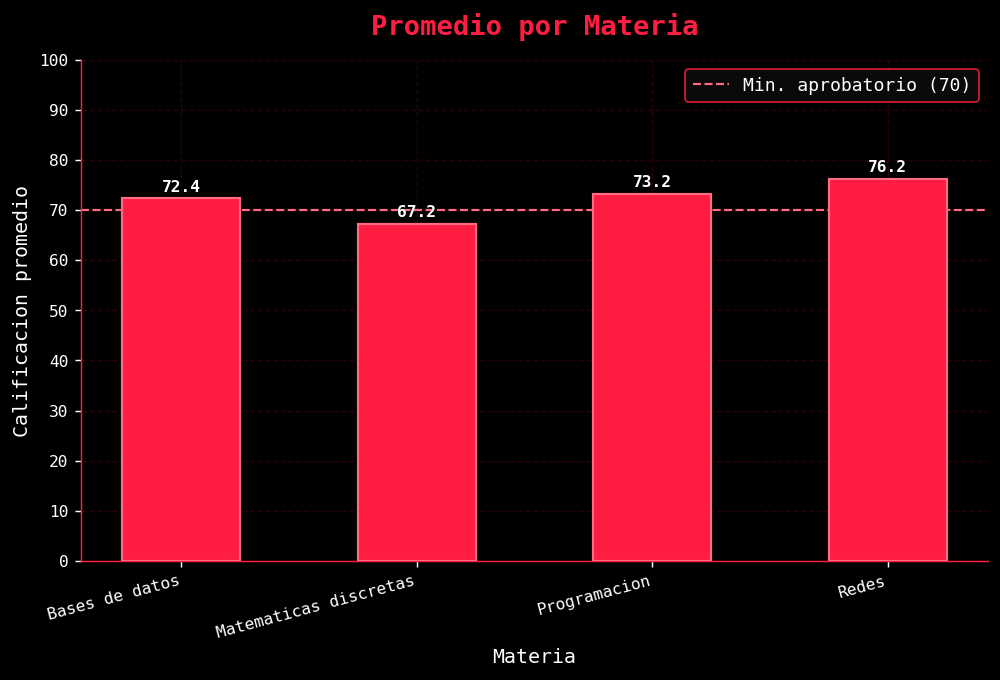

[OK] Guardada -> promedio_materias.png


In [13]:
# ── GRAFICA 1: Promedio por Materia (Barras) ──────────────────
fig, ax = plt.subplots(figsize=(9, 5))

materias_list = prom_materia.index.tolist()
valores       = prom_materia.values
x_pos         = np.arange(len(materias_list))

bars = ax.bar(x_pos, valores, color=ACCENT, width=0.5,
              edgecolor=ACCENT2, linewidth=1.2, zorder=3)

# Etiquetas de valor sobre cada barra
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.8,
            f"{val:.1f}",
            ha="center", va="bottom",
            color=WHITE, fontsize=9, fontweight="bold")

ax.set_xticks(x_pos)
ax.set_xticklabels(materias_list, rotation=15, ha="right")
ax.set_ylim(0, 100)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_title("Promedio por Materia", fontsize=15, fontweight="bold",
             color=ACCENT, pad=14)
ax.set_xlabel("Materia")
ax.set_ylabel("Calificacion promedio")
ax.axhline(70, color=ACCENT2, linewidth=1.2, linestyle="--",
           label="Min. aprobatorio (70)", zorder=2)
ax.legend()

plt.savefig(OUT_BAR, bbox_inches="tight", dpi=150)
plt.show()
print(f"[OK] Guardada -> {OUT_BAR}")

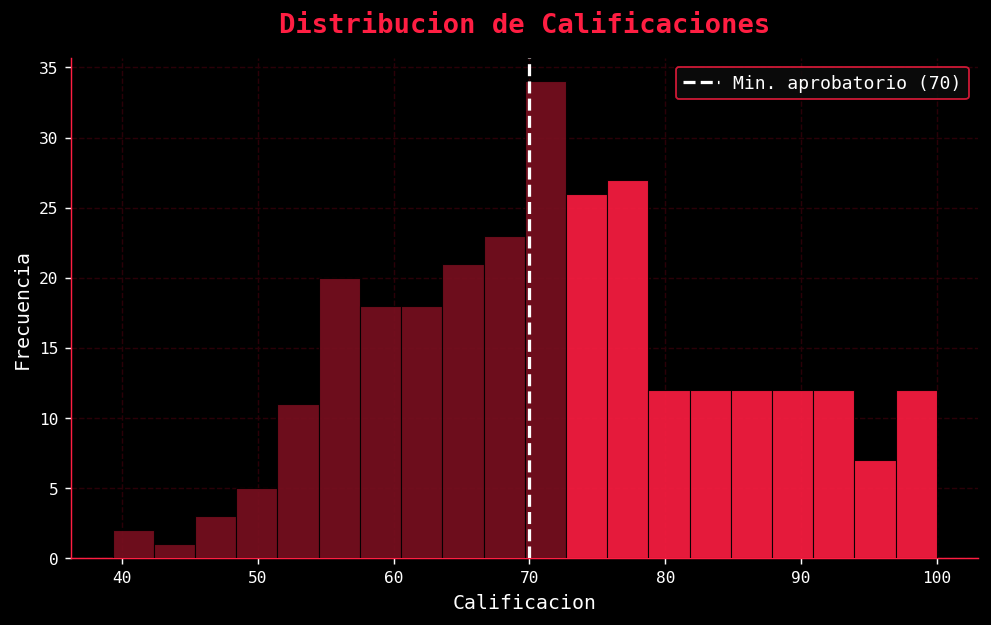

[OK] Guardada -> histograma.png


In [14]:
# ── GRAFICA 2: Histograma de Calificaciones ───────────────────
fig, ax = plt.subplots(figsize=(9, 5))

n, bins, patches = ax.hist(
    df["calificacion"], bins=20,
    color=ACCENT, edgecolor=BG, linewidth=0.6, zorder=3, alpha=0.9
)

# Resaltar barras reprobatorias (< 70) en rojo oscuro
for patch, left in zip(patches, bins[:-1]):
    if left < 70:
        patch.set_facecolor("#7a0f20")

# Linea vertical en el minimo aprobatorio
ax.axvline(70, color=WHITE, linewidth=1.8, linestyle="--",
           label="Min. aprobatorio (70)", zorder=4)

ax.set_title("Distribucion de Calificaciones", fontsize=15,
             fontweight="bold", color=ACCENT, pad=14)
ax.set_xlabel("Calificacion")
ax.set_ylabel("Frecuencia")
ax.legend()

plt.savefig(OUT_HIST, bbox_inches="tight", dpi=150)
plt.show()
print(f"[OK] Guardada -> {OUT_HIST}")

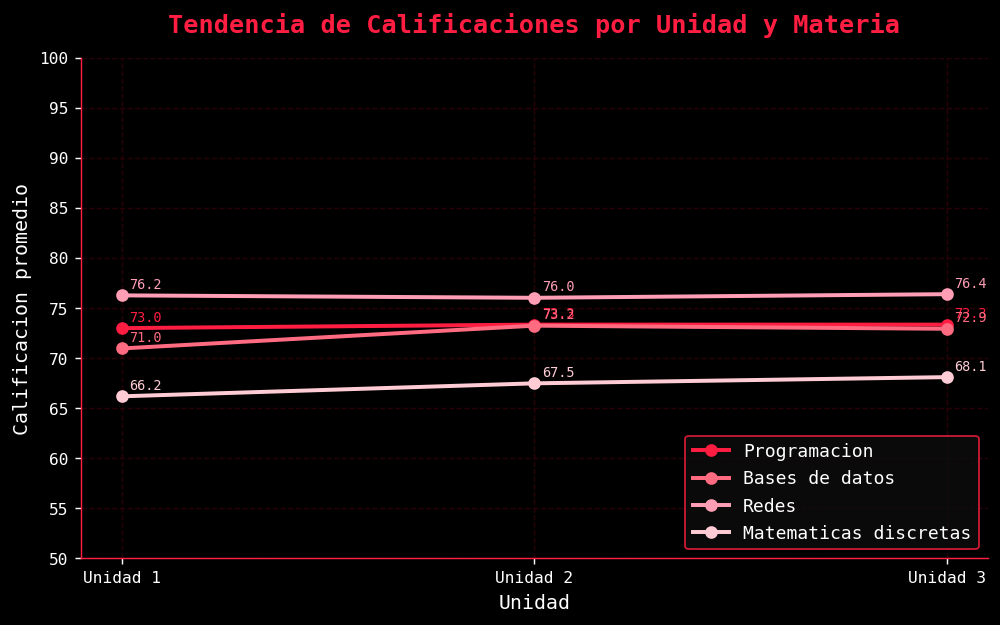

[OK] Guardada -> tendencia_unidades.png


In [15]:
# ── GRAFICA 3: Tendencia por Unidad y Materia (Lineas) ────────
fig, ax = plt.subplots(figsize=(9, 5))

materias_uniq = df["materia"].unique()
unidades_list = sorted(df["unidad"].unique())

for mat, color in zip(materias_uniq, COLORS):
    promedios = (
        df[df["materia"] == mat]
          .groupby("unidad")["calificacion"]
          .mean()
          .reindex(unidades_list)
    )
    ax.plot(unidades_list, promedios.values,
            marker="o", linewidth=2.2,
            color=color, label=mat, zorder=3)
    # Anotacion del valor en cada punto
    for u, v in zip(unidades_list, promedios.values):
        ax.annotate(f"{v:.1f}",
                    xy=(u, v), xytext=(4, 4),
                    textcoords="offset points",
                    color=color, fontsize=7.5)

ax.set_xticks(unidades_list)
ax.set_xticklabels([f"Unidad {u}" for u in unidades_list])
ax.set_ylim(50, 100)
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
ax.set_title("Tendencia de Calificaciones por Unidad y Materia",
             fontsize=14, fontweight="bold", color=ACCENT, pad=14)
ax.set_xlabel("Unidad")
ax.set_ylabel("Calificacion promedio")
ax.legend(loc="lower right")

plt.savefig(OUT_LINE, bbox_inches="tight", dpi=150)
plt.show()
print(f"[OK] Guardada -> {OUT_LINE}")

---
## 💡 Ejercicio 6 — Interpretación y Conclusiones

Con base en los resúmenes y gráficas calculados, respondemos las preguntas de análisis:

1. ¿Qué materia tiene el **menor promedio**?
2. ¿Cuál es la **tendencia** entre unidad 3 respecto a las unidades 1 y 2?
3. ¿Cuántos alumnos tienen un **promedio general menor a 70**?

In [16]:
print("=" * 58)
print("  EJERCICIO 6 — Interpretacion y Conclusiones")
print("=" * 58)

# ── 6.1 Materia con menor promedio ────────────────────────────
materia_min = prom_materia.idxmin()
val_min     = prom_materia.min()
print(f"\n[6.1] Materia con MENOR promedio: {materia_min} ({val_min:.2f})")

# ── 6.2 Tendencia por unidad ──────────────────────────────────
u1, u2, u3 = prom_unidad[1], prom_unidad[2], prom_unidad[3]

if u3 > u2 > u1:
    tendencia = "MEJORA progresivamente"
elif u3 < u2 < u1:
    tendencia = "EMPEORA progresivamente"
else:
    tendencia = "FLUCTUA (no hay tendencia lineal clara)"

print(f"\n[6.2] Tendencia por unidad:")
print(f"      Unidad 1: {u1:.2f}  |  Unidad 2: {u2:.2f}  |  Unidad 3: {u3:.2f}")
print(f"      => El rendimiento {tendencia} a lo largo de las unidades.")

# ── 6.3 Alumnos con promedio < 70 ────────────────────────────
prom_general = (
    df.groupby(["matricula", "nombre"])["calificacion"]
      .mean().round(2)
)
bajo_70      = (prom_general < 70).sum()
total_alum   = prom_general.shape[0]

print(f"\n[6.3] Alumnos con promedio general < 70: {bajo_70} de {total_alum}")

# ── 6.4 Porcentaje aprobados/reprobados ───────────────────────
conteo_pct = df["situacion"].value_counts(normalize=True) * 100
print("\n[6.4] Porcentaje global por situacion:")
for sit, pct in conteo_pct.items():
    print(f"      {sit}: {pct:.1f}%")

print("\n" + "=" * 58)
print("  Archivos generados:")
for f in [OUT_BAR, OUT_HIST, OUT_LINE, OUT_PROM]:
    existe = "[OK]" if os.path.exists(f) else "[!]"
    print(f"  {existe} {f}")
print("=" * 58)

  EJERCICIO 6 — Interpretacion y Conclusiones

[6.1] Materia con MENOR promedio: Matematicas discretas (67.24)

[6.2] Tendencia por unidad:
      Unidad 1: 71.59  |  Unidad 2: 72.51  |  Unidad 3: 72.67
      => El rendimiento MEJORA progresivamente a lo largo de las unidades.

[6.3] Alumnos con promedio general < 70: 13 de 24

[6.4] Porcentaje global por situacion:
      Aprobado: 57.3%
      Reprobado: 42.7%

  Archivos generados:
  [OK] promedio_materias.png
  [OK] histograma.png
  [OK] tendencia_unidades.png
  [OK] promedios_alumnos.csv


---
## ✅ Práctica Finalizada

| Entregable | Estado |
|------------|--------|
| `calificaciones_isc.csv` | 288 filas generadas |
| `promedios_alumnos.csv`  | 24 filas exportadas |
| `promedio_materias.png`  | Gráfica de barras Cyberpunk |
| `histograma.png`         | Histograma con línea en 70 |
| `tendencia_unidades.png` | Gráfica de líneas por unidad/materia |

---
*Práctica desarrollada con Python · Pandas · NumPy · Matplotlib*